In [1]:
!pip install -q transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn huggingface_hub

In [2]:
import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from datasets import Dataset

from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    multilabel_confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Hugging Face model repositories
MBERT_REPO = "Subha95/bengali-sentiment-bert"
XLMR_REPO = "Subha95/bengali-sentiment-xlmr-v2"

# Label order must match the order used during training
label_names = [
    "Positive",
    "Happiness",
    "Negative",
    "Sadness",
    "Question"
]

NUM_LABELS = len(label_names)

# Maximum sequence length used during training
MAX_LENGTH = 128

# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Number of labels:", NUM_LABELS)
print("Labels:", label_names)

Device: cuda
Number of labels: 5
Labels: ['Positive', 'Happiness', 'Negative', 'Sadness', 'Question']


In [4]:
# Load mBERT tokenizer and model
mbert_tokenizer = AutoTokenizer.from_pretrained(MBERT_REPO)

mbert_model = AutoModelForSequenceClassification.from_pretrained(
    MBERT_REPO
).to(device)


# Load XLM-R tokenizer and model
xlmr_tokenizer = AutoTokenizer.from_pretrained(XLMR_REPO)

xlmr_model = AutoModelForSequenceClassification.from_pretrained(
    XLMR_REPO
).to(device)


# Set both models to evaluation mode
mbert_model.eval()
xlmr_model.eval()

print("Both models loaded successfully!")

config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/352 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Both models loaded successfully!


In [5]:
print("========== mBERT CONFIGURATION ==========")

print("Model type:", mbert_model.config.model_type)
print("Number of labels:", mbert_model.config.num_labels)
print("Problem type:", mbert_model.config.problem_type)
print("Label mapping:", mbert_model.config.id2label)


print("\n========== XLM-R CONFIGURATION ==========")

print("Model type:", xlmr_model.config.model_type)
print("Number of labels:", xlmr_model.config.num_labels)
print("Problem type:", xlmr_model.config.problem_type)
print("Label mapping:", xlmr_model.config.id2label)


========== mBERT CONFIGURATION ==========
Model type: bert
Number of labels: 5
Problem type: multi_label_classification
Label mapping: {0: 'Positive', 1: 'Happiness', 2: 'Negative', 3: 'Sadness', 4: 'Question'}

========== XLM-R CONFIGURATION ==========
Model type: xlm-roberta
Number of labels: 5
Problem type: multi_label_classification
Label mapping: {0: 'Positive', 1: 'Happiness', 2: 'Negative', 3: 'Sadness', 4: 'Question'}


In [6]:
from google.colab import files

uploaded = files.upload()

Saving bengali_sentences_final.csv to bengali_sentences_final (1).csv


In [7]:
# Get uploaded filename
file_name = list(uploaded.keys())[0]

# Load CSV
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5182, 6)

Columns:
['Sentence', 'Positive', 'Negative', 'Question', 'Happiness', 'Sadness']

First 5 rows:


,Sentence,Positive,Negative,Question,Happiness,Sadness
0,পড়ছি আর নিজের মনে হাসছি।,1,0,0,1,0
1,"বাবা টেনি, তুমি আমায় ধনে-প্রাণে বাঁচিয়েছ।",1,0,0,1,0
2,"কাঙ্গা নেপালীর ছেলে, জান দিয়ে দেবে, কিন্তু মন...",0,1,0,0,0
3,এ যাত্রা আপনি ওকে নিয়ে যাবেন না।,0,1,0,0,0
4,কিছু কি নেই?,0,1,1,0,0



Missing values:
Sentence     0
Positive     0
Negative     0
Question     0
Happiness    0
Sadness      0
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from datasets import Dataset

# Select columns and replace NaN with 0
selected_df = df.iloc[:, 0:6].copy().fillna(0)

selected_df.columns = [
    "sentence",
    "Positive",
    "Negative",
    "Question",
    "Happiness",
    "Sadness"
]

# Create Hugging Face dataset
hf_dataset = Dataset.from_pandas(selected_df)

# Create multi-label vectors in the original training order
def process_labels(example):
    example["labels"] = [
        float(example["Positive"]),
        float(example["Happiness"]),
        float(example["Negative"]),
        float(example["Sadness"]),
        float(example["Question"])
    ]
    return example

hf_dataset = hf_dataset.map(process_labels)

# Keep only sentence and labels
hf_dataset = hf_dataset.remove_columns([
    "Positive",
    "Happiness",
    "Negative",
    "Sadness",
    "Question"
])

# Convert to DataFrame
df1 = hf_dataset.to_pandas()

# Reproduce original split
train_df, temp_df = train_test_split(
    df1,
    test_size=0.3,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Total:", len(df1))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Map:   0%|          | 0/5182 [00:00<?, ? examples/s]

Total: 5182
Training: 3627
Validation: 777
Test: 778


In [9]:
print("Test dataset shape:", test_df.shape)

print("\nFirst 5 test samples:")
display(test_df.head())

print("\nLabel distribution in test set:")

y_test = np.array(test_df["labels"].tolist()).astype(int)

for i, label in enumerate(label_names):
    print(f"{label}: {y_test[:, i].sum()}")

Test dataset shape: (778, 2)

First 5 test samples:


,sentence,labels
1538,এখনও কি ব্যাপারটা বলে দিতে হবে?,"[0.0, 0.0, 0.0, 0.0, 1.0]"
3133,দেখা নেই তো সব।,"[0.0, 0.0, 1.0, 0.0, 0.0]"
4263,"এই কম্বলটা এত গরম আর আরামদায়ক, শীতে দারুণ কাজ...","[1.0, 1.0, 0.0, 0.0, 0.0]"
3091,"জীবহিংসা কর না, তবে পাঁঠা খাও ক্যান?","[0.0, 0.0, 1.0, 0.0, 1.0]"
4828,আমার জীবনের যা সর্বশ্রেষ্ঠ আনন্দ তা পেয়েছিলাম...,"[1.0, 1.0, 0.0, 0.0, 0.0]"



Label distribution in test set:
Positive: 288
Happiness: 185
Negative: 279
Sadness: 198
Question: 208


In [10]:
# Extract test sentences
test_texts = test_df["sentence"].tolist()

# Extract ground-truth multi-label vectors
y_test = np.array(
    test_df["labels"].tolist()
).astype(int)

print("Number of test sentences:", len(test_texts))
print("Ground-truth shape:", y_test.shape)

print("\nFirst 3 test sentences:")
for i in range(3):
    print("Sentence:", test_texts[i])
    print("Labels:", y_test[i])
    print()

Number of test sentences: 778
Ground-truth shape: (778, 5)

First 3 test sentences:
Sentence: এখনও কি ব্যাপারটা বলে দিতে হবে?
Labels: [0 0 0 0 1]

Sentence: দেখা নেই তো সব।
Labels: [0 0 1 0 0]

Sentence: এই কম্বলটা এত গরম আর আরামদায়ক, শীতে দারুণ কাজে দেয়।
Labels: [1 1 0 0 0]



In [11]:
from scipy.special import expit
from torch.utils.data import DataLoader, TensorDataset

def predict_model(model, tokenizer, texts, batch_size=16):

    model.eval()

    all_probabilities = []

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[start:start + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            outputs = model(**inputs)

        probabilities = torch.sigmoid(outputs.logits)

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    return np.concatenate(all_probabilities, axis=0)

In [12]:
# mBERT predictions
mbert_probabilities = predict_model(
    mbert_model,
    mbert_tokenizer,
    test_texts
)

# XLM-R predictions
xlmr_probabilities = predict_model(
    xlmr_model,
    xlmr_tokenizer,
    test_texts
)

print("mBERT probability shape:", mbert_probabilities.shape)
print("XLM-R probability shape:", xlmr_probabilities.shape)

print("\nFirst test sentence:")
print(test_texts[0])

print("\nGround truth:", y_test[0])
print("mBERT probabilities:", np.round(mbert_probabilities[0], 4))
print("XLM-R probabilities:", np.round(xlmr_probabilities[0], 4))

mBERT probability shape: (778, 5)
XLM-R probability shape: (778, 5)

First test sentence:
এখনও কি ব্যাপারটা বলে দিতে হবে?

Ground truth: [0 0 0 0 1]
mBERT probabilities: [0.0143 0.0204 0.0155 0.0246 0.9827]
XLM-R probabilities: [0.0117 0.0141 0.0209 0.0625 0.9945]


In [13]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# Default threshold
THRESHOLD = 0.5

# Convert probabilities into binary predictions
mbert_predictions = (
    mbert_probabilities >= THRESHOLD
).astype(int)

xlmr_predictions = (
    xlmr_probabilities >= THRESHOLD
).astype(int)


# Calculate evaluation metrics
def calculate_metrics(y_true, y_pred):

    return {
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Micro F1": f1_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Exact Match Accuracy": accuracy_score(
            y_true, y_pred
        )
    }


mbert_metrics = calculate_metrics(y_test, mbert_predictions)
xlmr_metrics = calculate_metrics(y_test, xlmr_predictions)


# Display comparison
comparison_df = pd.DataFrame({
    "Metric": mbert_metrics.keys(),
    "mBERT": mbert_metrics.values(),
    "XLM-R": xlmr_metrics.values()
})

comparison_df["mBERT (%)"] = (
    comparison_df["mBERT"] * 100
).round(2)

comparison_df["XLM-R (%)"] = (
    comparison_df["XLM-R"] * 100
).round(2)

display(
    comparison_df[
        ["Metric", "mBERT (%)", "XLM-R (%)"]
    ]
)

,Metric,mBERT (%),XLM-R (%)
0,Macro F1,93.34,91.56
1,Micro F1,94.44,93.17
2,Macro Precision,94.80,94.43
3,Macro Recall,92.04,89.24
4,Exact Match Accuracy,86.25,83.42


In [14]:
from sklearn.metrics import classification_report

# Generate classification reports
mbert_report = classification_report(
    y_test,
    mbert_predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

xlmr_report = classification_report(
    y_test,
    xlmr_predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

# Compare individual labels
per_label_comparison = []

for label in label_names:

    per_label_comparison.append({
        "Label": label,

        "mBERT Precision": mbert_report[label]["precision"],
        "XLM-R Precision": xlmr_report[label]["precision"],

        "mBERT Recall": mbert_report[label]["recall"],
        "XLM-R Recall": xlmr_report[label]["recall"],

        "mBERT F1": mbert_report[label]["f1-score"],
        "XLM-R F1": xlmr_report[label]["f1-score"]
    })

per_label_df = pd.DataFrame(per_label_comparison)

# Display percentages
display(
    per_label_df.set_index("Label").mul(100).round(2)
)

,mBERT Precision,XLM-R Precision,mBERT Recall,XLM-R Recall,mBERT F1,XLM-R F1
Label,,,,,,
Positive,100.00,98.95,98.26,98.61,99.12,98.78
Happiness,91.53,90.61,93.51,88.65,92.51,89.62
Negative,99.64,99.64,100.00,99.64,99.82,99.64
Sadness,83.33,83.44,73.23,63.64,77.96,72.21
Question,99.50,99.50,95.19,95.67,97.30,97.55


In [15]:
# Extract validation sentences
val_texts = val_df["sentence"].tolist()

# Extract validation ground-truth labels
y_val = np.array(
    val_df["labels"].tolist()
).astype(int)

# Generate mBERT validation probabilities
mbert_val_probabilities = predict_model(
    mbert_model,
    mbert_tokenizer,
    val_texts
)

# Generate XLM-R validation probabilities
xlmr_val_probabilities = predict_model(
    xlmr_model,
    xlmr_tokenizer,
    val_texts
)

print("Validation samples:", len(val_texts))
print("Ground truth shape:", y_val.shape)

print("mBERT validation probabilities:",
      mbert_val_probabilities.shape)

print("XLM-R validation probabilities:",
      xlmr_val_probabilities.shape)

Validation samples: 777
Ground truth shape: (777, 5)
mBERT validation probabilities: (777, 5)
XLM-R validation probabilities: (777, 5)


In [16]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.10, 0.91, 0.01)


def optimize_thresholds(probabilities, y_true, labels):

    best_thresholds = {}

    for i, label in enumerate(labels):

        best_f1 = 0
        best_threshold = 0.5

        for threshold in thresholds:

            y_pred = (
                probabilities[:, i] >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, i],
                y_pred,
                zero_division=0
            )

            if score > best_f1:
                best_f1 = score
                best_threshold = threshold

        best_thresholds[label] = best_threshold

    return best_thresholds


# Optimize each model independently
mbert_best_thresholds = optimize_thresholds(
    mbert_val_probabilities,
    y_val,
    label_names
)

xlmr_best_thresholds = optimize_thresholds(
    xlmr_val_probabilities,
    y_val,
    label_names
)


# Display threshold comparison
threshold_comparison = pd.DataFrame({
    "Label": label_names,
    "mBERT Threshold": [
        mbert_best_thresholds[label] for label in label_names
    ],
    "XLM-R Threshold": [
        xlmr_best_thresholds[label] for label in label_names
    ]
})

display(threshold_comparison)

,Label,mBERT Threshold,XLM-R Threshold
0,Positive,0.15,0.20
1,Happiness,0.47,0.39
2,Negative,0.33,0.46
3,Sadness,0.27,0.35
4,Question,0.18,0.12


In [17]:
# Convert threshold dictionaries into arrays
mbert_threshold_values = np.array([
    mbert_best_thresholds[label] for label in label_names
])

xlmr_threshold_values = np.array([
    xlmr_best_thresholds[label] for label in label_names
])


# Apply optimized thresholds to test probabilities
mbert_tuned_predictions = (
    mbert_probabilities >= mbert_threshold_values
).astype(int)

xlmr_tuned_predictions = (
    xlmr_probabilities >= xlmr_threshold_values
).astype(int)


# Calculate metrics
mbert_tuned_metrics = calculate_metrics(
    y_test,
    mbert_tuned_predictions
)

xlmr_tuned_metrics = calculate_metrics(
    y_test,
    xlmr_tuned_predictions
)


# Display comparison
tuned_comparison_df = pd.DataFrame({
    "Metric": mbert_tuned_metrics.keys(),
    "mBERT (%)": [
        value * 100 for value in mbert_tuned_metrics.values()
    ],
    "XLM-R (%)": [
        value * 100 for value in xlmr_tuned_metrics.values()
    ]
})

display(
    tuned_comparison_df.round(2)
)

,Metric,mBERT (%),XLM-R (%)
0,Macro F1,93.56,91.70
1,Micro F1,94.34,93.09
2,Macro Precision,92.88,92.32
3,Macro Recall,94.28,91.22
4,Exact Match Accuracy,85.48,83.29


In [18]:
mbert_tuned_report = classification_report(
    y_test,
    mbert_tuned_predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

xlmr_tuned_report = classification_report(
    y_test,
    xlmr_tuned_predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

tuned_per_label = []

for label in label_names:

    tuned_per_label.append({
        "Label": label,

        "mBERT Precision": mbert_tuned_report[label]["precision"],
        "XLM-R Precision": xlmr_tuned_report[label]["precision"],

        "mBERT Recall": mbert_tuned_report[label]["recall"],
        "XLM-R Recall": xlmr_tuned_report[label]["recall"],

        "mBERT F1": mbert_tuned_report[label]["f1-score"],
        "XLM-R F1": xlmr_tuned_report[label]["f1-score"]
    })

tuned_per_label_df = pd.DataFrame(tuned_per_label)

display(
    tuned_per_label_df.set_index("Label").mul(100).round(2)
)

,mBERT Precision,XLM-R Precision,mBERT Recall,XLM-R Recall,mBERT F1,XLM-R F1
Label,,,,,,
Positive,98.62,98.28,98.96,98.96,98.79,98.62
Happiness,91.53,88.83,93.51,90.27,92.51,89.54
Negative,98.94,99.64,100.00,99.64,99.47,99.64
Sadness,76.78,78.61,81.82,68.69,79.22,73.32
Question,98.54,96.24,97.12,98.56,97.82,97.39


In [19]:
import time

def benchmark_latency(model, tokenizer, texts, batch_size=16, runs=5):

    # Warm-up run
    predict_model(
        model,
        tokenizer,
        texts[:batch_size]
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    timings = []

    for _ in range(runs):

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        predict_model(
            model,
            tokenizer,
            texts,
            batch_size=batch_size
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end_time = time.perf_counter()

        timings.append(end_time - start_time)

    average_time = np.mean(timings)

    return {
        "Average total time (seconds)": average_time,
        "Average time per sentence (ms)": (
            average_time / len(texts)
        ) * 1000,
        "Throughput (sentences/second)": (
            len(texts) / average_time
        )
    }


mbert_latency = benchmark_latency(
    mbert_model,
    mbert_tokenizer,
    test_texts
)

xlmr_latency = benchmark_latency(
    xlmr_model,
    xlmr_tokenizer,
    test_texts
)

latency_df = pd.DataFrame({
    "Metric": mbert_latency.keys(),
    "mBERT": mbert_latency.values(),
    "XLM-R": xlmr_latency.values()
})

display(latency_df.round(4))

,Metric,mBERT,XLM-R
0,Average total time (seconds),2.2438,1.7295
1,Average time per sentence (ms),2.8841,2.2230
2,Throughput (sentences/second),346.7345,449.8466


In [20]:
def get_model_info(model):

    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    parameter_memory = sum(
        parameter.numel() * parameter.element_size()
        for parameter in model.parameters()
    )

    buffer_memory = sum(
        buffer.numel() * buffer.element_size()
        for buffer in model.buffers()
    )

    return {
        "Total parameters (Millions)": total_parameters / 1e6,
        "Trainable parameters (Millions)": trainable_parameters / 1e6,
        "Parameter memory (MB)": parameter_memory / (1024 ** 2),
        "Total model memory (MB)": (parameter_memory + buffer_memory) / (1024 ** 2),
        "Data type": str(next(model.parameters()).dtype)
    }


mbert_info = get_model_info(mbert_model)
xlmr_info = get_model_info(xlmr_model)

model_size_df = pd.DataFrame({
    "Metric": mbert_info.keys(),
    "mBERT": mbert_info.values(),
    "XLM-R": xlmr_info.values()
})

display(model_size_df.round(2))

,Metric,mBERT,XLM-R
0,Total parameters (Millions),177.857285,278.047493
1,Trainable parameters (Millions),177.857285,278.047493
2,Parameter memory (MB),678.471699,1060.667011
3,Total model memory (MB),678.479511,1060.674854
4,Data type,torch.float32,torch.float32


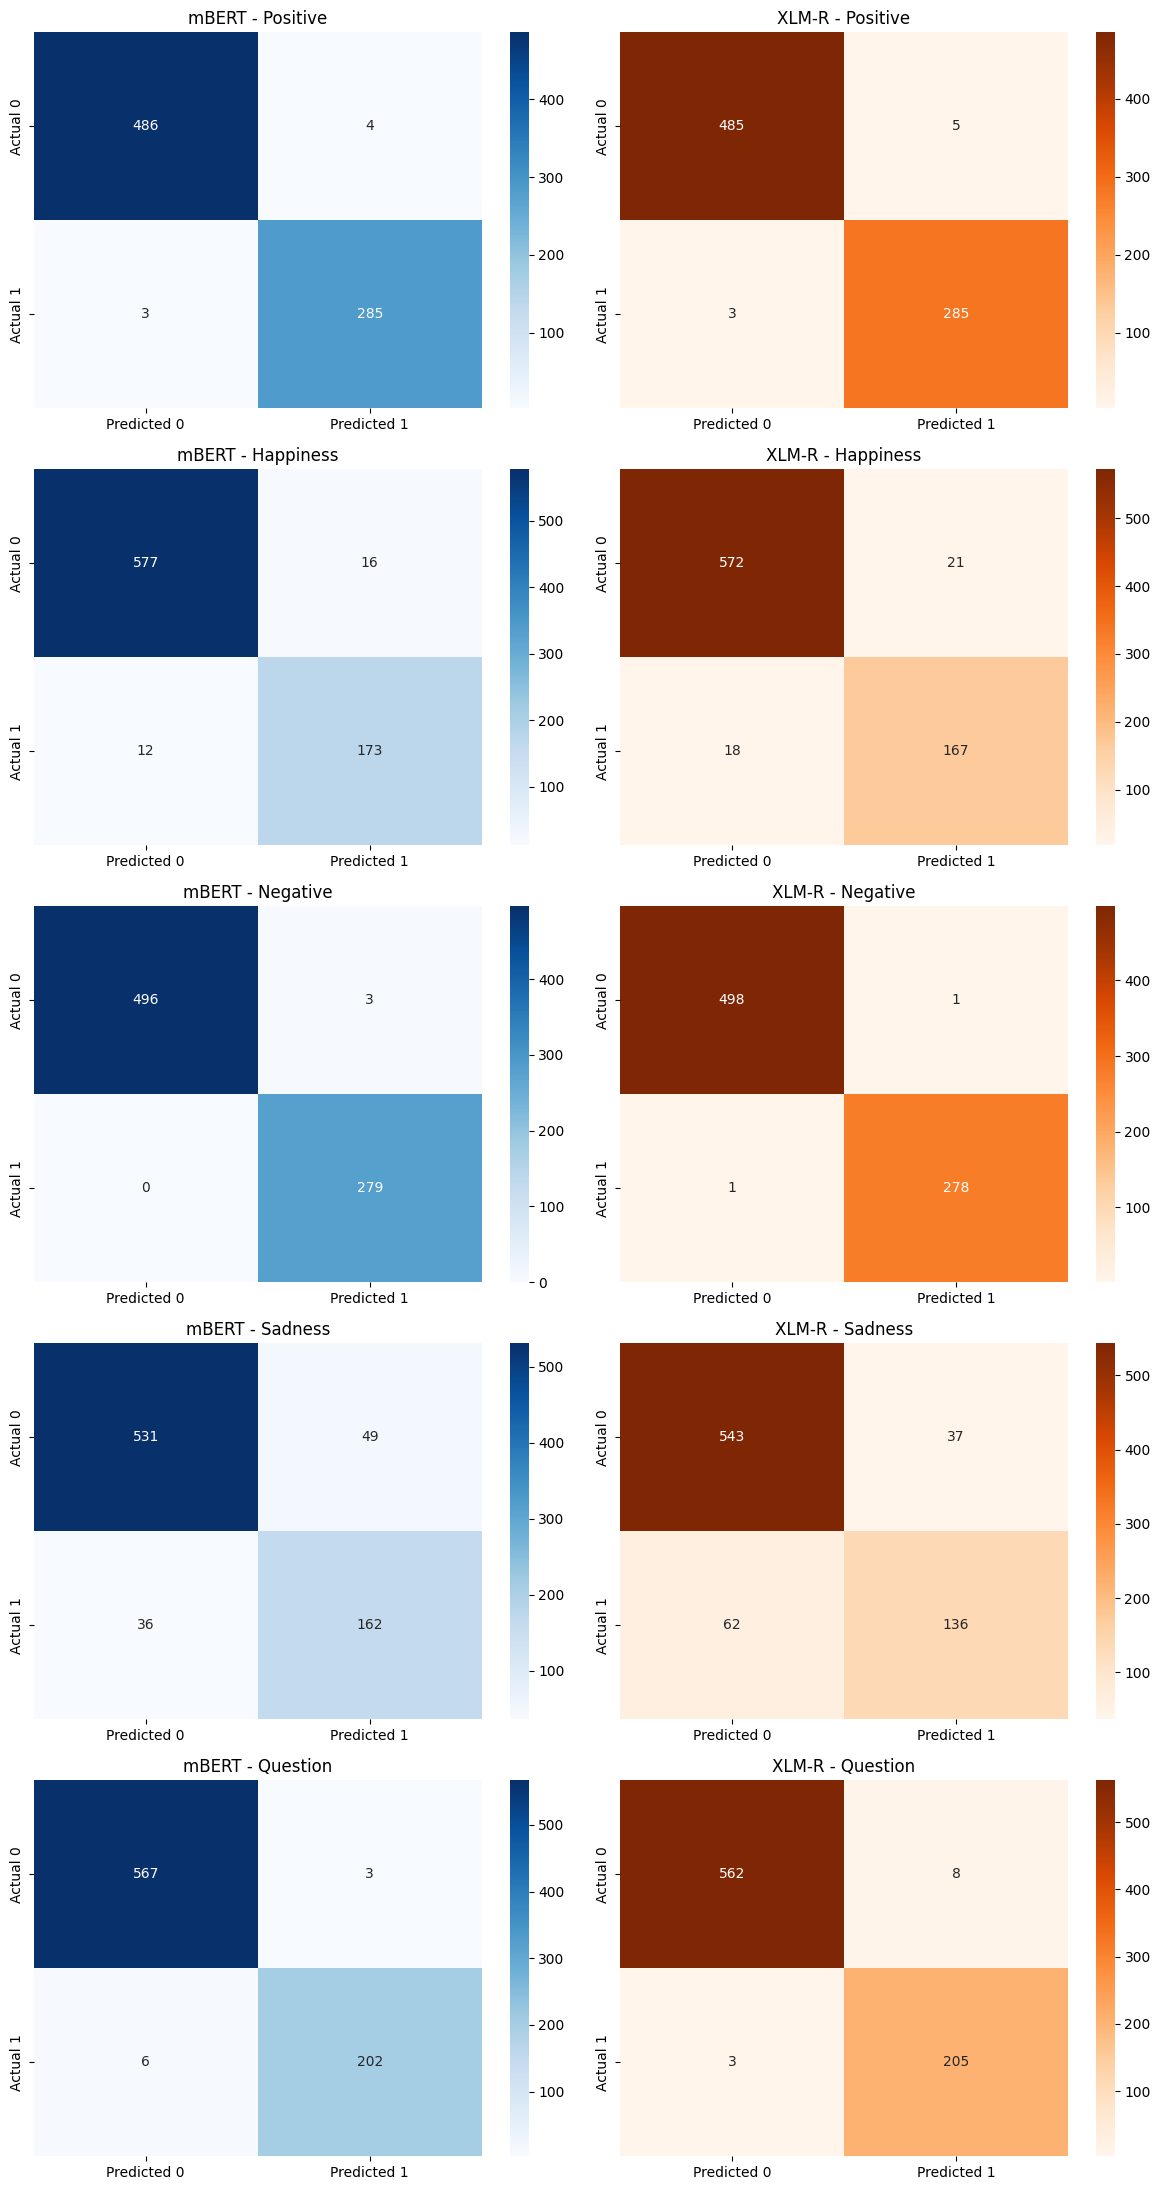

In [21]:
mbert_cm = multilabel_confusion_matrix(
    y_test,
    mbert_tuned_predictions
)

xlmr_cm = multilabel_confusion_matrix(
    y_test,
    xlmr_tuned_predictions
)

fig, axes = plt.subplots(5, 2, figsize=(12, 22))

for i, label in enumerate(label_names):

    sns.heatmap(
        mbert_cm[i],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"mBERT - {label}")

    sns.heatmap(
        xlmr_cm[i],
        annot=True,
        fmt="d",
        cmap="Oranges",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"XLM-R - {label}")

plt.tight_layout()
plt.show()

In [22]:
import json

deployment_config = {
    "model_name": MBERT_REPO,
    "base_model": "google-bert/bert-base-multilingual-cased",
    "problem_type": "multi_label_classification",
    "max_length": MAX_LENGTH,
    "labels": label_names,
    "thresholds": {
        label: float(mbert_best_thresholds[label])
        for label in label_names
    }
}

with open("deployment_config.json", "w") as f:
    json.dump(deployment_config, f, indent=4)

print(json.dumps(deployment_config, indent=4))

{
    "model_name": "Subha95/bengali-sentiment-bert",
    "base_model": "google-bert/bert-base-multilingual-cased",
    "problem_type": "multi_label_classification",
    "max_length": 128,
    "labels": [
        "Positive",
        "Happiness",
        "Negative",
        "Sadness",
        "Question"
    ],
    "thresholds": {
        "Positive": 0.14999999999999997,
        "Happiness": 0.46999999999999986,
        "Negative": 0.32999999999999985,
        "Sadness": 0.2699999999999999,
        "Question": 0.17999999999999997
    }
}
